# A/B Test Halaman E-commerce

**Pertanyaan bisnis**  
Apakah halaman baru meningkatkan konversi cukup besar untuk layak dirilis?

Data latihan berasal dari [repositori resmi Udacity](https://github.com/udacity/sdand-ab-testing-project/tree/e3aeae691f434eff812bd3c9c4a6f8c7cc2ec5df). Grup `control` mewakili halaman lama dan `treatment` mewakili halaman baru. Unit observasi adalah satu baris CSV. Perhitungan interval mengasumsikan observasi independen.

**Aturan keputusan**

- Gunakan selisih tingkat konversi treatment dikurangi control dan interval kepercayaan 95% dua sisi.
- Asumsikan **+0,5 poin persentase** sebagai ambang bisnis untuk studi kasus ini, setara dengan lima konversi tambahan per 1.000 observasi.
- Jika batas bawah interval melebihi ambang, pertimbangkan rilis setelah validitas eksperimen dikonfirmasi. Jika batas atas di bawah ambang, pertahankan halaman lama. Jika interval mencakup ambang, rencanakan tes lanjutan.
- Konfirmasi konfigurasi alokasi dan proses pencatatan sebelum mengambil keputusan rilis.

In [1]:
from hashlib import sha256
from math import sqrt
from pathlib import Path
from statistics import NormalDist

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from scipy.stats import binomtest
from statsmodels.stats.proportion import confint_proportions_2indep

DATA_PATH = Path("ab_data.csv")
SOURCE_SHA256 = "8c1ce3d02b7b195c1f40a1c278ba8c2f807295874c302efb61812ba226ce43ac"
MINIMUM_LIFT = 0.005
ALPHA = 0.05
ASSUMED_TREATMENT_SHARE = 0.50

if not DATA_PATH.is_file():
    raise FileNotFoundError("Unduh ab_data.csv dari README dan simpan di folder notebook.")
if sha256(DATA_PATH.read_bytes()).hexdigest() != SOURCE_SHA256:
    raise ValueError("CSV berbeda dari versi sumber. Unduh ulang file Raw dari tautan di README.")

observations = pd.read_csv(DATA_PATH)

## 1. Validasi data dan pembagian trafik

Periksa skema, nilai kosong, dan kategori sebelum menghitung metrik. CSV hanya memuat `country`, `group`, dan `converted`. Baris dengan kombinasi nilai identik bisa mewakili observasi yang berbeda, sehingga semua baris yang valid dipertahankan. Pemeriksaan duplikasi pengguna, kecocokan paparan halaman, dan pola alokasi dari waktu ke waktu membutuhkan ID pengguna, versi halaman yang dilihat, dan timestamp.

In [2]:
expected_columns = {"country", "group", "converted"}
if set(observations.columns) != expected_columns or observations.empty:
    raise ValueError("CSV kosong atau skemanya berbeda dari sumber.")
if observations.isna().any().any():
    raise ValueError("CSV memiliki nilai kosong.")
if set(observations["group"]) != {"control", "treatment"}:
    raise ValueError("Kolom group harus memuat kedua grup eksperimen.")
if not observations["converted"].isin([0, 1]).all():
    raise ValueError("Kolom converted hanya boleh memuat 0 dan 1.")
if not observations["country"].isin(["CA", "UK", "US"]).all():
    raise ValueError("Ditemukan kode negara di luar CA, UK, dan US.")

print(f"Baris valid: {len(observations):,}")
print(f"Total nilai kosong: {observations.isna().sum().sum()}")

Baris valid: 69,889
Total nilai kosong: 0


Jika setiap observasi punya peluang independen 50% untuk masuk treatment, uji binomial dua sisi dapat mendeteksi *sample ratio mismatch* (SRM). Rasio yang direncanakan tidak tersedia, sehingga hasil ini adalah diagnostik bersyarat.

In [3]:
country_counts = pd.crosstab(observations["country"], observations["group"])
country_audit = country_counts.assign(
    treatment_share=country_counts["treatment"] / country_counts.sum(axis=1),
    treatment_minus_control=country_counts["treatment"] - country_counts["control"],
)
display(country_audit.assign(
    treatment_share=country_audit["treatment_share"].map("{:.2%}".format),
))

group_counts = country_counts.sum()
allocation = binomtest(
    int(group_counts["treatment"]), int(group_counts.sum()), p=ASSUMED_TREATMENT_SHARE
)
net_gap = int(group_counts["treatment"] - group_counts["control"])
largest_gap_country = country_audit["treatment_minus_control"].abs().idxmax()
largest_gap = int(country_audit.loc[largest_gap_country, "treatment_minus_control"])

print(f"Selisih treatment dan control keseluruhan: {net_gap:+,} observasi")
print(f"Kontribusi terbesar menurut jumlah: {largest_gap_country} ({largest_gap:+,})")
print(f"Proporsi treatment keseluruhan: {allocation.statistic:.2%}")
print(f"p-value diagnostik alokasi terhadap 50/50: {allocation.pvalue:.4f}")
if allocation.pvalue < ALPHA:
    print("Jika targetnya 50/50, pembagian trafik perlu diinvestigasi.")

group,control,treatment,treatment_share,treatment_minus_control
country,,,,
CA,1683,1805,51.75%,122
UK,8795,8756,49.89%,-39
US,24200,24650,50.46%,450


Selisih treatment dan control keseluruhan: +533 observasi
Kontribusi terbesar menurut jumlah: US (+450)
Proporsi treatment keseluruhan: 50.38%
p-value diagnostik alokasi terhadap 50/50: 0.0442
Jika targetnya 50/50, pembagian trafik perlu diinvestigasi.


US menyumbang selisih terbesar berdasarkan jumlah (+450 dari selisih bersih +533). CA memiliki proporsi treatment tertinggi (51,75%). Gunakan rincian ini sebagai titik awal untuk memeriksa log penugasan dan pencatatan. Rincian per negara bersifat deskriptif.

## 2. Estimasi dampak pada konversi

Tingkat konversi adalah jumlah baris dengan `converted = 1` dibagi jumlah baris dalam grup. Metode Newcombe memberikan interval kepercayaan selisih dua proporsi independen.

In [4]:
summary = (
    observations.groupby("group")["converted"]
    .agg(observations="size", conversions="sum", conversion_rate="mean")
    .reindex(["control", "treatment"])
)
control = summary.loc["control"]
treatment = summary.loc["treatment"]
lift = treatment.conversion_rate - control.conversion_rate
lower, upper = confint_proportions_2indep(
    count1=int(treatment.conversions),
    nobs1=int(treatment.observations),
    count2=int(control.conversions),
    nobs2=int(control.observations),
    compare="diff",
    method="newcomb",
    alpha=ALPHA,
)

display(summary.assign(conversion_rate=summary["conversion_rate"].map("{:.2%}".format)))
print(f"Selisih: {lift * 100:+.2f} poin persentase")
print(f"Interval kepercayaan 95%: {lower * 100:+.2f} hingga {upper * 100:+.2f} poin persentase")

,observations,conversions,conversion_rate
group,,,
control,34678,3650,10.53%
treatment,35211,5469,15.53%


Selisih: +5.01 poin persentase
Interval kepercayaan 95%: +4.51 hingga +5.50 poin persentase


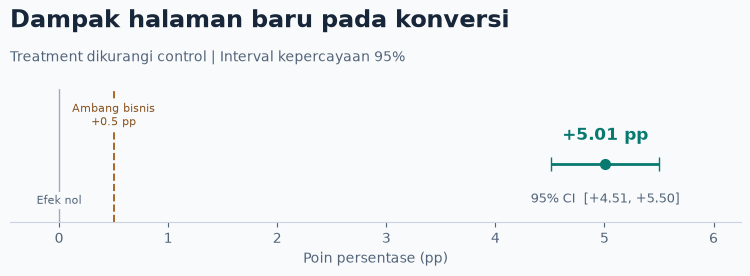

In [5]:
ink, teal, muted = "#18263A", "#08796F", "#54657A"
background = "#F8FAFC"
fig, ax = plt.subplots(figsize=(8.4, 3.1), facecolor=background)
fig.subplots_adjust(left=0.09, right=0.96, top=0.68, bottom=0.25)
fig.text(0.09, 0.88, "Dampak halaman baru pada konversi",
         color=ink, fontsize=17, fontweight="bold")
fig.text(0.09, 0.77, "Treatment dikurangi control | Interval kepercayaan 95%",
         color=muted, fontsize=10)

ax.set_facecolor(background)
ax.axvline(0, color="#A0ADBD", linewidth=1)
ax.axvline(MINIMUM_LIFT * 100, color="#A86625", linestyle="--", linewidth=1.4)
label_box = dict(facecolor=background, edgecolor="none", pad=2)
ax.text(0, 0.14, "Efek nol", ha="center", color=muted, fontsize=8, bbox=label_box)
ax.text(MINIMUM_LIFT * 100, 0.73, f"Ambang bisnis\n+{MINIMUM_LIFT * 100:g} pp",
        ha="center", color="#88511D", fontsize=8, bbox=label_box)

lift_pp = lift * 100
ax.errorbar(lift_pp, 0.44, xerr=[[(lift - lower) * 100], [(upper - lift) * 100]],
            fmt="o", color=teal, capsize=5, elinewidth=2, markersize=7)
ax.text(lift_pp, 0.62, f"{lift_pp:+.2f} pp", ha="center",
        color=teal, fontweight="bold", fontsize=12)
ax.text(lift_pp, 0.15, f"95% CI  [{lower * 100:+.2f}, {upper * 100:+.2f}]",
        ha="center", color=muted, fontsize=9)

ax.set(xlim=(-0.45, 6.25), ylim=(0, 1), yticks=[], xlabel="Poin persentase (pp)")
ax.xaxis.label.set_color(muted)
ax.tick_params(axis="x", colors=muted)
for spine in ("top", "left", "right"):
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_color("#CAD4E0")
fig.savefig("conversion-lift.png", dpi=160)
plt.show()

## 3. Uji sensitivitas terhadap komposisi negara

Estimasi utama membandingkan tingkat konversi mentah kedua grup. Untuk melihat pengaruh komposisi geografis, hitung selisih tingkat konversi di tiap negara, lalu ambil rata-rata tertimbang menggunakan proporsi negara dari seluruh observasi. Kedua grup dibandingkan pada komposisi negara gabungan yang sama.

Interval 95% memakai pendekatan normal dengan bobot gabungan dianggap tetap. Dengan asumsi observasi independen, varians selisih per negara adalah jumlah varians dua proporsi binomial. Varians estimasi tertimbang adalah jumlah varians per negara dikalikan kuadrat bobot masing-masing.

In [6]:
country_rates = observations.groupby(["country", "group"])["converted"].mean().unstack()
country_weights = country_counts.sum(axis=1) / len(observations)
country_lifts = country_rates["treatment"] - country_rates["control"]
adjusted_lift = (country_weights * country_lifts).sum()

rate_variances = country_rates * (1 - country_rates) / country_counts
lift_variances = rate_variances.sum(axis=1)
adjusted_se = sqrt((country_weights.pow(2) * lift_variances).sum())
margin = NormalDist().inv_cdf(1 - ALPHA / 2) * adjusted_se
adjusted_lower, adjusted_upper = adjusted_lift - margin, adjusted_lift + margin

display(pd.DataFrame({
    "weight": country_weights.map("{:.2%}".format),
    "control_rate": country_rates["control"].map("{:.2%}".format),
    "treatment_rate": country_rates["treatment"].map("{:.2%}".format),
    "lift_pp": (100 * country_lifts).map("{:+.2f}".format),
}))
comparison = pd.DataFrame(
    [(lift, lower, upper), (adjusted_lift, adjusted_lower, adjusted_upper)],
    index=["Observed", "Country-standardized"],
    columns=["lift_pp", "ci_lower_pp", "ci_upper_pp"],
)
display((100 * comparison).round(4))
print(f"Perubahan setelah standardisasi: {(adjusted_lift - lift) * 100:+.4f} poin persentase")

,weight,control_rate,treatment_rate,lift_pp
country,,,,
CA,4.99%,9.45%,15.40%,+5.95
UK,25.11%,10.16%,14.87%,+4.70
US,69.90%,10.73%,15.78%,+5.05


,lift_pp,ci_lower_pp,ci_upper_pp
Observed,5.0067,4.5092,5.5042
Country-standardized,5.0053,4.5079,5.5027


Perubahan setelah standardisasi: -0.0014 poin persentase


Estimasi bergeser sekitar 0,0014 poin persentase. Setelah dibulatkan, keduanya menunjukkan lift +5,01 poin persentase dan interval 95% +4,51 hingga +5,50 poin. Hasil tetap melampaui ambang +0,50 poin setelah komposisi negara disamakan. Validitas penugasan dan pencatatan tetap perlu dikonfirmasi lewat log eksperimen.

## 4. Keputusan rilis

**Tunda rilis penuh hingga alokasi diverifikasi.** Kenaikan konversi melampaui ambang bisnis +0,50 poin persentase, termasuk setelah komposisi negara disamakan. Jika targetnya 50/50, pembagian trafik perlu diselidiki.

Konfirmasi konfigurasi alokasi, lalu cocokkan log penugasan pengguna, paparan halaman, dan konversi. Mulai dari US untuk memeriksa selisih jumlah observasi terbesar. Jika integritas data terkonfirmasi, pertimbangkan rilis bertahap. Jika validitas eksperimen tetap meragukan, jalankan ulang dengan pencatatan penugasan dan paparan halaman pada tingkat pengguna.

## 5. Metrik pengaman untuk eksperimen berikutnya

Konversi tetap menjadi metrik utama. CSV Udacity hanya memuat hasil konversi biner, sehingga metrik pengaman di bawah adalah rancangan untuk tes berikutnya.

| Metrik | Cara hitung | Risiko yang dipantau |
| --- | --- | --- |
| Pendapatan bersih per pengguna | Total nilai produk setelah diskon dan refund, dibagi semua pengguna yang ditugaskan ke grup, termasuk pengguna yang tidak membeli. Gunakan satu mata uang pelaporan. | Konversi naik, tetapi pendapatan per pengguna turun. |
| Tingkat refund | Persentase pesanan berbayar yang menerima refund penuh atau sebagian. Hitung setiap pesanan maksimal satu kali. | Proporsi pesanan yang berakhir dengan refund naik. |

**Jendela usulan.** Masukkan pesanan berbayar dalam 7 hari sejak pengguna ditugaskan dan amati refund hingga 30 hari sejak pembayaran masing-masing pesanan. Catat ID pengguna, grup dan waktu penugasan, ID pesanan, waktu pembayaran, nilai produk setelah diskon, mata uang, serta waktu dan nilai refund.

**Aturan rilis.** Sebelum tes dimulai, sepakati penurunan pendapatan per pengguna dan kenaikan tingkat refund maksimum yang bisa diterima. Setelah jendela pengukuran lengkap, hitung interval kepercayaan 95% untuk selisih treatment dikurangi control dengan bootstrap pada tingkat pengguna di masing-masing grup. Bawa semua pesanan pengguna yang sama dalam setiap pengambilan sampel. Pertimbangkan rilis jika alokasi valid, konversi memenuhi kriteria utama, batas bawah interval selisih pendapatan berada di atas batas penurunan, dan batas atas interval selisih tingkat refund berada di bawah batas kenaikan. Jika hasil metrik pengaman belum meyakinkan, tunda rilis penuh.